# Portfolio construction and backtest

In [1]:
import sys

sys.path.insert(0, "..")
import pandas as pd
import config

P = config.PATHS
pd.read_csv(P.tables / "summary_metrics.csv", index_col=0)

,AnnReturn,AnnVol,Sharpe,Sortino,MaxDrawdown,Calmar,CVaR5,AnnTurnover,Months
BL_ML_Regime,0.076991,0.082283,0.779840,1.218433,-0.162767,0.473010,-0.050262,4.365179,211.0
BL_ML_Regime_IC,0.074734,0.070897,0.863156,1.374039,-0.132969,0.562041,-0.038664,1.916160,211.0
BL_ML_NoRegime,0.075641,0.093370,0.683692,1.027855,-0.228259,0.331383,-0.062631,5.025355,211.0
BL_HistMean_Regime,0.079595,0.073826,0.893913,1.457713,-0.153128,0.519792,-0.038948,1.342525,211.0
Market_Reference,0.103939,0.097418,0.926883,1.519080,-0.210603,0.493530,-0.055646,0.345936,211.0
Equal_Weight,0.094899,0.112512,0.743854,1.299958,-0.235862,0.402351,-0.058937,0.540171,211.0
Static_60_40,0.103733,0.091176,0.980462,1.595831,-0.205222,0.505469,-0.051941,0.265035,211.0
Inverse_Vol,0.066374,0.071303,0.748663,1.185394,-0.177275,0.374415,-0.041878,0.461058,211.0
MeanVariance_LW,0.059977,0.132818,0.402221,0.616532,-0.369744,0.162211,-0.081104,2.524840,211.0
Regime_60_40,0.082348,0.069463,0.979789,1.551506,-0.131488,0.626282,-0.038587,1.190564,211.0


In [2]:
pd.read_csv(P.tables / "significance.csv")

,strategy,benchmark,diff,ci_low,ci_high,p_value,n
0,BL_ML_Regime,BL_ML_Regime_IC,-0.083316,-0.286171,0.114053,0.412147,211
1,BL_ML_Regime,BL_ML_NoRegime,0.096148,-0.032207,0.206479,0.119220,211
2,BL_ML_Regime,BL_HistMean_Regime,-0.114073,-0.351074,0.101431,0.333417,211
3,BL_ML_Regime,Market_Reference,-0.147043,-0.405750,0.075714,0.230442,211
4,BL_ML_Regime,Equal_Weight,0.035987,-0.275783,0.347310,0.818045,211
5,BL_ML_Regime,Static_60_40,-0.200622,-0.527864,0.074173,0.197201,211
6,BL_ML_Regime,Inverse_Vol,0.031178,-0.288128,0.294793,0.834291,211
7,BL_ML_Regime,MeanVariance_LW,0.377619,0.015670,0.751586,0.044989,211
8,BL_ML_Regime,Regime_60_40,-0.199948,-0.538694,0.099015,0.227443,211
9,BL_ML_Regime,Regime_Market,-0.130508,-0.370718,0.107859,0.286178,211


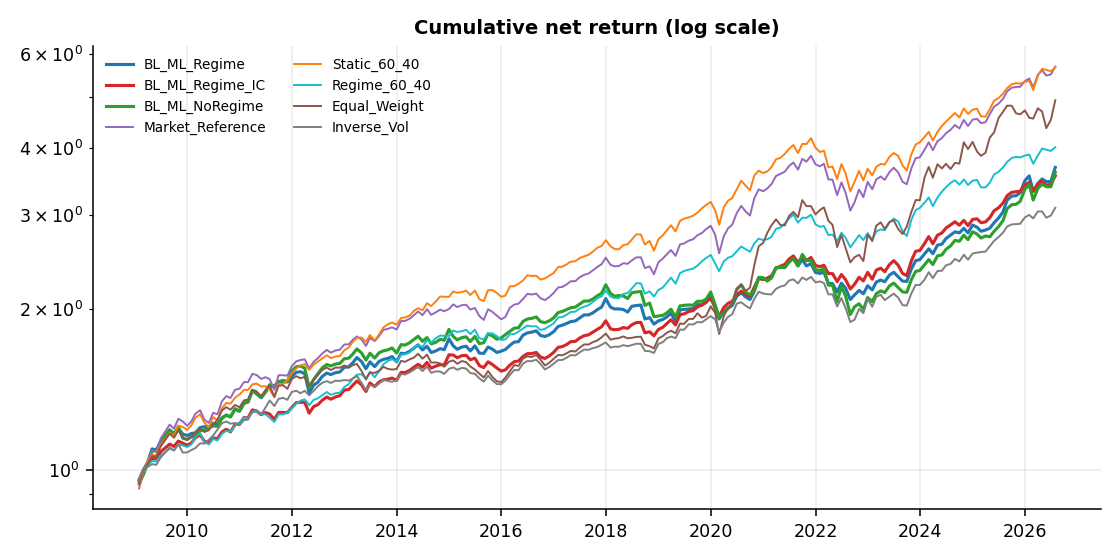

In [3]:
from IPython.display import Image

Image(str(P.figures / "07_cumulative_returns.png"))

In [4]:
pd.read_csv(P.tables / "regime_metrics.csv", index_col=[0, 1])

AnnReturn    AnnVol    Sharpe   Sortino  \
BL_ML_Regime       All        0.076991  0.082283  0.779840  1.218433   
                   Calm       0.074020  0.084358  0.711663  1.102370   
                   Stressed   0.083131  0.078420  0.925423  1.486832   
BL_ML_Regime_IC    All        0.074734  0.070897  0.863156  1.374039   
                   Calm       0.068298  0.071640  0.748352  1.174859   
                   Stressed   0.088101  0.069725  1.101157  1.816618   
BL_ML_NoRegime     All        0.075641  0.093370  0.683692  1.027855   
                   Calm       0.074218  0.084330  0.714099  1.106271   
                   Stressed   0.078576  0.110339  0.647394  0.946667   
BL_HistMean_Regime All        0.079595  0.073826  0.893913  1.457713   
                   Calm       0.073200  0.074377  0.786033  1.277304   
                   Stressed   0.092876  0.073092  1.114721  1.839798   
Market_Reference   All        0.103939  0.097418  0.926883  1.519080   
                   Calm       0.075984  0.074823  0.816134  1.288680   
                   Stressed   0.163775  0.131488  1.146670  1.913965   
Equal_Weight       All        0.094899  0.112512  0.743854  1.299958   
                   Calm       0.057008  0.094981  0.471497  0.806763   
                   Stressed   0.177207  0.140178  1.169160  2.055228   
Static_60_40       All        0.103733  0.091176  0.980462  1.595831   
                   Calm       0.080392  0.070113  0.922228  1.435876   
                   Stressed   0.153368  0.123258  1.140569  1.906032   
Inverse_Vol        All        0.066374  0.071303  0.748663  1.185394   
                   Calm       0.055294  0.060090  0.674895  1.087121   
                   Stressed   0.089546  0.090259  0.885495  1.381842   
MeanVariance_LW    All        0.059977  0.132818  0.402221  0.616532   
                   Calm       0.038848  0.114899  0.255875  0.366346   
                   Stressed   0.104822  0.163822  0.627872  1.042592   
Regime_60_40       All        0.082348  0.069463  0.979789  1.551506   
                   Calm       0.079598  0.070123  0.911538  1.415967   
                   Stressed   0.088031  0.068567  1.117040  1.861110   
Regime_Market      All        0.081244  0.074160  0.910349  1.456206   
                   Calm       0.075202  0.074840  0.806140  1.269599   
                   Stressed   0.093785  0.073171  1.124443  1.872131   

                             MaxDrawdown    Calmar     CVaR5  AnnTurnover  \
BL_ML_Regime       All         -0.162767  0.473010 -0.050262     4.365179   
                   Calm        -0.108065  0.684952 -0.049511     4.562143   
                   Stressed    -0.111121  0.748112 -0.046665     3.959833   
BL_ML_Regime_IC    All         -0.132969  0.562041 -0.038664     1.916160   
                   Calm        -0.102967  0.663300 -0.037549     1.932668   
                   Stressed    -0.097291  0.905541 -0.039127     1.882189   
BL_ML_NoRegime     All         -0.228259  0.331383 -0.062631     5.025355   
                   Calm        -0.107841  0.688215 -0.049524     4.378653   
                   Stressed    -0.180212  0.436021 -0.068280     6.356249   
BL_HistMean_Regime All         -0.153128  0.519792 -0.038948     1.342525   
                   Calm        -0.109076  0.671089 -0.036517     1.149277   
                   Stressed    -0.109151  0.850894 -0.040609     1.740224   
Market_Reference   All         -0.210603  0.493530 -0.055646     0.345936   
                   Calm        -0.105625  0.719375 -0.038783     0.245336   
                   Stressed    -0.182973  0.895074 -0.073540     0.552969   
Equal_Weight       All         -0.235862  0.402351 -0.058937     0.540171   
                   Calm        -0.132361  0.430700 -0.041971     0.433661   
                   Stressed    -0.211637  0.837312 -0.074612     0.759366   
Static_60_40       All         -0.205222  0.505469 -0.051941     0.265035   
                   Calm        -0.099669

In [5]:
pd.read_csv(P.tables / "cost_sensitivity.csv", index_col=0)

,0bps,10bps,25bps,50bps
BL_ML_Regime,0.832706,0.779840,0.700353,0.567481
BL_ML_Regime_IC,0.890621,0.863156,0.821881,0.752939
BL_ML_NoRegime,0.737548,0.683692,0.602782,0.467722
BL_HistMean_Regime,0.912742,0.893913,0.865634,0.818432
Market_Reference,0.930855,0.926883,0.920921,0.910976
Equal_Weight,0.748848,0.743854,0.736358,0.723855
Static_60_40,0.983801,0.980462,0.975448,0.967074
Inverse_Vol,0.755557,0.748663,0.738318,0.721066
MeanVariance_LW,0.421113,0.402221,0.373841,0.326436
Regime_60_40,0.997639,0.979789,0.952928,0.907971
